# Milestone 1: PACS data source, exploration and preparation

Project: which pretraining generalises? We compare vision backbones (supervised ResNet-50, self-supervised DINOv2, language-supervised CLIP) under domain shift, with DomainBed on PACS.

The notebook goes through the same steps as `prepare_data.py`, one at a time:

1. data source and download
2. data exploration and visualization
3. data preparation (leave-one-domain-out splits)
4. final output: training, validation and test inputs and outputs

In [1]:
# Colab: get the repository (code and split files) and install the only missing package
import os
if not os.path.exists('PACS-DomainGeneralization'):
    !git clone -q https://github.com/Ch0ng3/PACS-DomainGeneralization.git
os.chdir('PACS-DomainGeneralization')
%pip -q install datasets

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import prepare_data as pdp
DATA_DIR = 'data'
pd.set_option('display.width', 140)

Note: you may need to restart the kernel to use updated packages.


## 1. Data source and download

PACS was introduced by Li et al. in *Deeper, Broader and Artier Domain Generalization* (ICCV 2017, https://arxiv.org/abs/1710.03077). It has 9,991 images of 7 classes (dog, elephant, giraffe, guitar, horse, house, person) in 4 domains (art painting, cartoon, photo, sketch).

DomainBed's download script (`download_pacs` in `domainbed/scripts/download.py`) gets the original archive from Google Drive with `gdown`. This download often fails because of the Google Drive quota, so we use the copy on Hugging Face, `flwrlabs/pacs` (https://huggingface.co/datasets/flwrlabs/pacs), as the project description allows. It has the same 9,991 images.

`pdp.download_pacs` loads the dataset with the Hugging Face `datasets` library (`load_dataset('flwrlabs/pacs', split='train')`) and saves each image as an RGB JPEG (quality 95) in the folder layout DomainBed reads:

```
data/PACS/<domain>/<class>/<00000>.jpg
```

Files are numbered per domain and class in the order of the Hugging Face dataset, so the layout is the same on every machine. The images are not stored in the repository, so the function downloads them the first time it runs. If `data/PACS` already has all 9,991 images, for example when the cell runs a second time, it skips the download.

In [2]:
class_names = pdp.download_pacs(DATA_DIR)
print('classes:', class_names)
print('images on disk:', pdp.count_images(os.path.join(DATA_DIR, 'PACS')))

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  191MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9991 [00:00<?, ? examples/s]

written 0/9991


written 2000/9991


written 4000/9991


written 6000/9991


written 8000/9991


PACS ready in data/PACS: 9991 images
classes: ['dog', 'elephant', 'giraffe', 'guitar', 'horse', 'house', 'person']
images on disk: 9991


## 2. Data exploration and visualization

`pdp.build_index` reads every image once and makes a table with one row per image, in the order DomainBed's `ImageFolder` uses (domains, classes and files sorted). For each image it stores the size, three pixel statistics (brightness, contrast, colorfulness) and the MD5 hash of the file, which we use to look for duplicates.

In [3]:
index = pdp.build_index(DATA_DIR)
print(index.shape)
index.head()

(9991, 11)


,path,domain,class_name,label,index_in_domain,width,height,brightness,contrast,colorfulness,md5
0,PACS/art_painting/dog/00000.jpg,art_painting,dog,0,0,227,227,0.513202,0.270463,0.060542,a8d7d24f7ed970b748647c6c8698b3fe
1,PACS/art_painting/dog/00001.jpg,art_painting,dog,0,1,227,227,0.438180,0.218380,0.097118,215baa9c566d4206bdc540efd6999c9a
2,PACS/art_painting/dog/00002.jpg,art_painting,dog,0,2,227,227,0.404176,0.207077,0.027446,f3b0e5f8d0ff923746a81e54bf7498f4
3,PACS/art_painting/dog/00003.jpg,art_painting,dog,0,3,227,227,0.625317,0.329972,0.102438,045a418e784cf3a6e2046c4976bca95f
4,PACS/art_painting/dog/00004.jpg,art_painting,dog,0,4,227,227,0.425873,0.266544,0.120018,f43098a97ab8f52c141bef032186ff63


### 2.1 Images per domain and class

In [4]:
pdp.class_table(index)

class_name,dog,elephant,giraffe,guitar,horse,house,person,total
domain,,,,,,,,
art_painting,379,255,285,184,201,295,449,2048
cartoon,389,457,346,135,324,288,405,2344
photo,189,202,182,186,199,280,432,1670
sketch,772,740,753,608,816,80,160,3929
total,1729,1654,1566,1113,1540,943,1446,9991


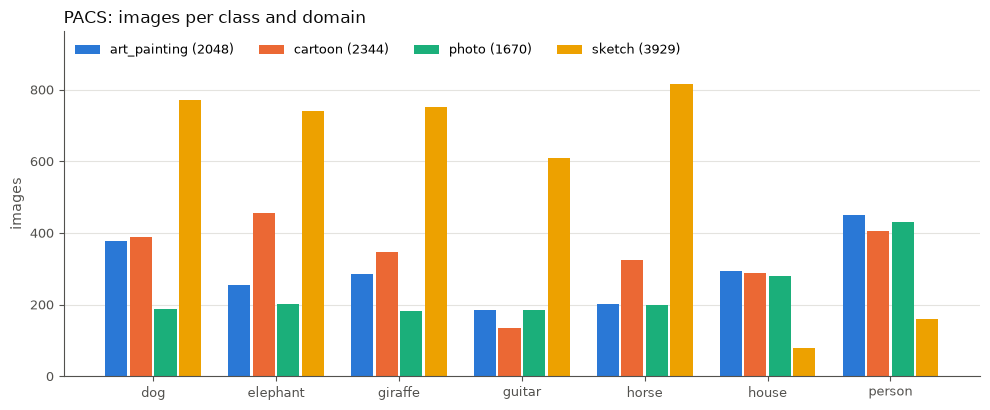

In [5]:
pdp.plot_class_distribution(index); plt.show()

Sketch has 3,929 images and photo only 1,670. The classes are not distributed the same way in every domain: sketch has only 80 houses and 160 persons, while person is the largest class in art painting and photo and one of the largest in cartoon. A model trained on 3 domains therefore learns a class prior that differs from the one of the test domain, and this is part of the domain shift.

Because of this imbalance, the accuracy on a held-out domain depends on its class mix. On sketch, for example, dog, elephant, giraffe, guitar and horse are 94% of the test images, so errors on them count much more than errors on house.

### 2.2 Example images

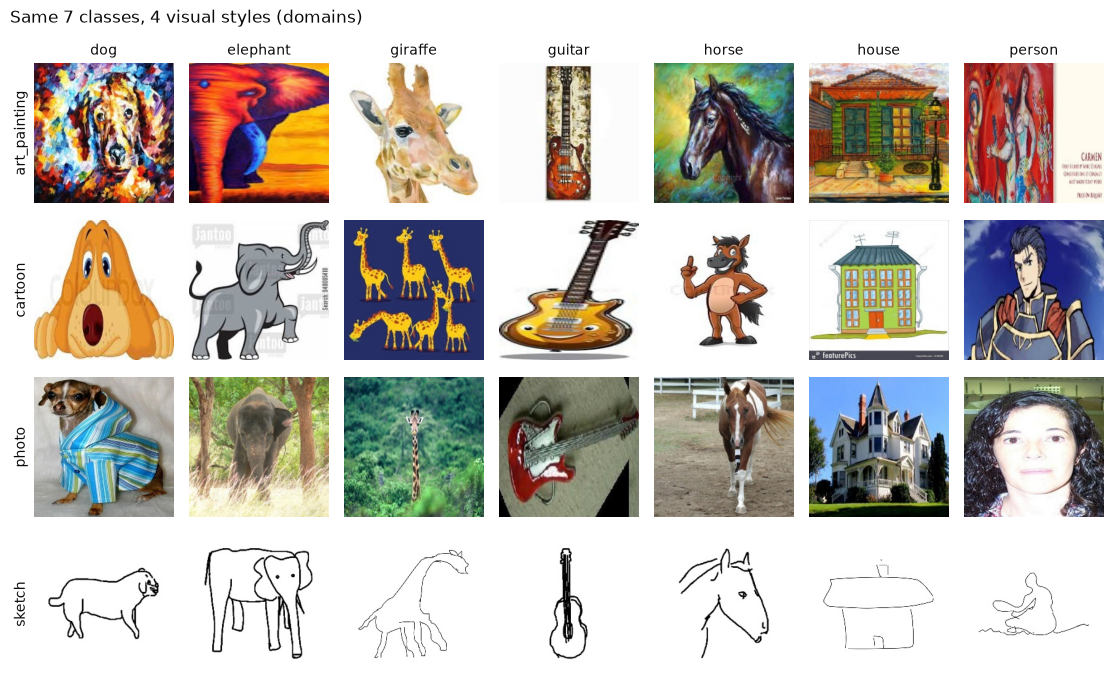

In [6]:
pdp.plot_samples(index, DATA_DIR); plt.show()

Photos have real textures and backgrounds, art paintings have strong colors and brush strokes, cartoons have flat colors and thick outlines, and sketches are black lines on a white background with no color or texture. A model that relies on texture or color to recognise the objects will therefore struggle most on sketches.

### 2.3 Image size and pixel statistics

In [7]:
print(index.groupby(['width', 'height']).size().rename('images'))
index.groupby('domain')[['brightness', 'contrast', 'colorfulness']].describe().round(3).T

width  height
227    227       9991
Name: images, dtype: int64


domain              art_painting   cartoon     photo    sketch
brightness   count      2048.000  2344.000  1670.000  3929.000
             mean          0.507     0.776     0.477     0.956
             std           0.152     0.117     0.117     0.017
             min           0.110     0.080     0.053     0.836
             25%           0.400     0.724     0.403     0.946
             50%           0.490     0.794     0.473     0.957
             75%           0.597     0.856     0.547     0.967
             max           0.957     0.973     0.924     0.993
contrast     count      2048.000  2344.000  1670.000  3929.000
             mean          0.202     0.248     0.235     0.183
             std           0.052     0.063     0.052     0.036
             min           0.042     0.048     0.083     0.079
             25%           0.167     0.204     0.200     0.163
             50%           0.199     0.249     0.235     0.186
             75%           0.235     0.290     0.266     0.207
             max           0.442     0.492     0.413     0.351
colorfulness count      2048.000  2344.000  1670.000  3929.000
             mean          0.076     0.052     0.053     0.000
             std           0.043     0.043     0.026     0.000
             min           0.000     0.000     0.000     0.000
             25%           0.045     0.022     0.037     0.000
             50%           0.069     0.042     0.049     0.000
             75%           0.097     0.071     0.063     0.000
             max           0.284     0.305     0.274     0.000

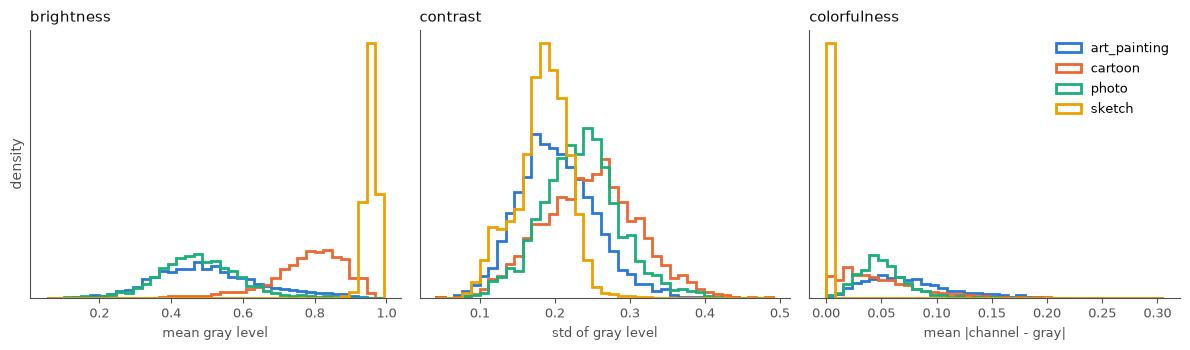

In [8]:
pdp.plot_pixel_stats(index); plt.show()

All images are 227 × 227 RGB, so they only need to be resized to the 224 × 224 input of the pretrained backbones.

Sketches are almost white (mean gray level 0.96) and their colorfulness is zero: they are grayscale images stored as RGB. Cartoons are also bright because of their white backgrounds. Photos and art paintings have similar brightness, but art paintings are more colorful.

Since the four domains have such different pixel statistics, statistics computed on one domain would not fit the others. We normalize with the ImageNet mean and std instead, which is what the ImageNet-pretrained backbones expect.

### 2.4 Duplicates

In [9]:
dups = pdp.duplicate_report(index)
print('groups of identical files:', len(dups))
dups.head()

groups of identical files: 0


,md5,copies,domains,classes,paths


No two files are identical, so the same image cannot end up in training and in validation or test. A hash does not find near-duplicates, such as the same picture with a different crop.

## 3. Data preparation

The goal is domain generalization, so we evaluate leave-one-domain-out: the model is trained on 3 domains and tested on the 4th, which it never sees during training or model selection. Each of the 4 domains is held out once, which gives 4 settings.

For the validation set we follow DomainBed. It splits every domain into an `in` part (80%) and an `out` part (20%, `--holdout_fraction 0.2`): for domain number `env_i` it shuffles the indices with the seed `seed_hash(trial_seed, env_i)` and takes the first 20% as `out`. `pdp.assign_parts` does the same with `trial_seed = 0`, so our splits match the ones DomainBed uses in training.

For each held-out (test) domain:

| split | content | used for |
|---|---|---|
| `train.csv` | `in` part (80%) of the 3 training domains | training |
| `val.csv` | `out` part (20%) of the 3 training domains | model selection (training-domain validation) |
| `test.csv` | all images of the held-out domain | final evaluation only |

We never use the test domain to choose a model or hyperparameters. DomainBed's oracle selection does use it, so it is not a fair result. Each CSV has the columns `path, domain, class_name, label, part`. The files hold only paths and labels: the images are read from `data/PACS/`, which `download_pacs` filled in section 1.

In `test.csv` the `part` column is still useful. DomainBed splits the held-out domain 80/20 like the others and reports the accuracy on its `in` part, so the ERM results in `Milestone1_ERM_reproduction.ipynb` are measured on the rows of `test.csv` with `part = in`.

In [10]:
summary = pdp.make_splits(index, DATA_DIR)
summary

split checks passed: disjoint splits, held-out domain unseen, all 7 classes everywhere


,test_domain,train,val,test
0,art_painting,6356,1587,2048
1,cartoon,6119,1528,2344
2,photo,6659,1662,1670
3,sketch,4851,1211,3929


Class distribution (%) in each split of one setting (test domain = sketch):

In [11]:
s = {n: pd.read_csv(f'{DATA_DIR}/splits/test_sketch/{n}.csv') for n in ['train', 'val', 'test']}
pd.DataFrame({n: df['class_name'].value_counts(normalize=True).mul(100).round(1) for n, df in s.items()})

,train,val,test
class_name,,,
dog,16.0,15.0,19.6
elephant,14.3,18.1,18.8
giraffe,13.5,13.2,19.2
guitar,8.5,7.8,15.5
horse,12.0,11.7,20.8
house,14.3,14.0,2.0
person,21.5,20.1,4.1


Train and validation have a similar class distribution, because the validation set is a random 20% of the same domains. The test domain is very different (2.0% houses and 4.1% persons, against about 14% and 21% in training), which is the label shift we saw in section 2.1. `pdp.check_splits` (output above) checks that the three splits do not overlap, that the held-out domain is not in train or validation, and that every split has all 7 classes.

## 4. Final output: inputs and outputs

The inputs `X` are float32 arrays of shape `(N, 3, 224, 224)`. Each image is resized from 227 to 224 and normalized with the ImageNet mean `(0.485, 0.456, 0.406)` and std `(0.229, 0.224, 0.225)`. Training images also get a DomainBed-style augmentation: random resized crop (70% to 100% of the area), horizontal flip, color jitter (0.3) and random grayscale (p = 0.1).

The outputs `y` are int64 class labels from 0 to 6, in the order of `class_names`.

`pdp.load_split(test_domain, split)` returns `(X, y)` for any split. The cell below loads 16 images from each split of every setting, because a whole split takes about 0.6 MB per image in memory. During training the images are loaded one batch at a time.

In [12]:
print('labels:', dict(enumerate(class_names)))
for d in pdp.DOMAINS:
    for split in ['train', 'val', 'test']:
        X, y = pdp.load_split(d, split, DATA_DIR, limit=16, train_aug=(split == 'train'))
        print(f'test_{d:13s} {split:5s}  X {X.shape} {X.dtype}  mean {X.mean():+.2f} std {X.std():.2f}   y {y.shape} {y.dtype}')

labels: {0: 'dog', 1: 'elephant', 2: 'giraffe', 3: 'guitar', 4: 'horse', 5: 'house', 6: 'person'}
test_art_painting  train  X (16, 3, 224, 224) float32  mean +1.04 std 1.38   y (16,) int64


test_art_painting  val    X (16, 3, 224, 224) float32  mean +1.60 std 1.34   y (16,) int64


test_art_painting  test   X (16, 3, 224, 224) float32  mean +0.20 std 1.20   y (16,) int64
test_cartoon       train  X (16, 3, 224, 224) float32  mean +1.22 std 1.27   y (16,) int64


test_cartoon       val    X (16, 3, 224, 224) float32  mean +1.09 std 1.47   y (16,) int64


test_cartoon       test   X (16, 3, 224, 224) float32  mean +1.42 std 1.30   y (16,) int64
test_photo         train  X (16, 3, 224, 224) float32  mean +1.47 std 1.17   y (16,) int64


test_photo         val    X (16, 3, 224, 224) float32  mean +1.57 std 1.19   y (16,) int64


test_photo         test   X (16, 3, 224, 224) float32  mean +0.20 std 1.24   y (16,) int64
test_sketch        train  X (16, 3, 224, 224) float32  mean +0.61 std 1.30   y (16,) int64


test_sketch        val    X (16, 3, 224, 224) float32  mean +0.36 std 1.45   y (16,) int64


test_sketch        test   X (16, 3, 224, 224) float32  mean +2.24 std 0.79   y (16,) int64


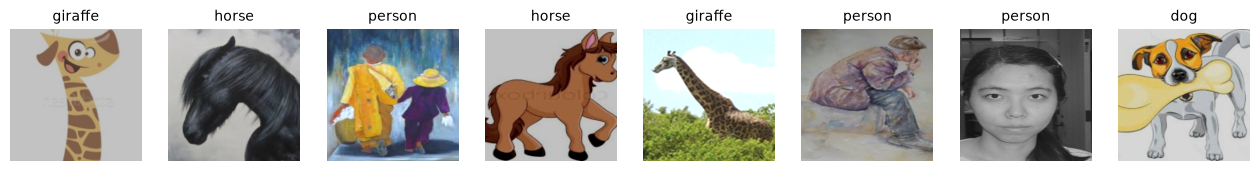

In [13]:
# what the model sees: augmented training inputs (normalization undone for display)
X, y = pdp.load_split('sketch', 'train', DATA_DIR, limit=8, train_aug=True, seed=1)
img = (X.transpose(0, 2, 3, 1) * pdp.IMAGENET_STD + pdp.IMAGENET_MEAN).clip(0, 1)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, im, lab in zip(axes, img, y):
    ax.imshow(im); ax.set_title(class_names[lab], fontsize=10); ax.axis('off')
plt.show()

## Conclusion

We now have PACS on disk in DomainBed's layout and four leave-one-domain-out settings with train, validation and test files in `data/splits/`. The exploration showed that the domains differ in size, class mix and pixel statistics, with sketch as the most different domain. `Milestone1_ERM_reproduction.ipynb` trains ERM with ResNet-50 on the same splits; in the next milestones we compare it with DINOv2 and CLIP backbones.